In [1]:
from reasoning_aware_irt.toy_scenarios import make_reasoning_aware_3pl_toy, build_scenarios

In [2]:
toy_list, names = build_scenarios()
print(names, len(toy_list))

['fail_budget_leverage_items', 'fail_budget_response', 'fail_confounding', 'fail_effective_rank', 'fail_fisher_proxy', 'fail_variance_ceiling', 'fail_variance_floor', 'pass_all'] 8


In [3]:
from reasoning_aware_irt.toy_scenarios import DataPreChecker
import numpy as np

avg_Y_list = [float(np.mean(t['Y_ij'])) for t in toy_list]

# results_list = []
passes = []
warns = []
all_results = {}
for i, toy in enumerate(toy_list):
    print('\n', names[i])
    chk = DataPreChecker(Y_ij=toy['Y_ij'], B_ij=toy['B_ij'], P_ij=toy.get('P_ij'))
    ok, warn, res = chk.run_all_tests()
    all_results[names[i]] = res
    # results_list.append(res)
    passes.append(ok)
    warns.append(warn)


print("passes:", passes)
print("warns:", warns)


 fail_budget_leverage_items
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[FAIL] Budget Leverage: Items OK=0.20, Models OK=1.00
[PASS] Effective Rank=30.50, Ratio=0.94
[PASS] Ability-Budget Confounding Corr=-0.1017
[WARN] Budget-Response Association: Signal Prop=0.055 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.125 with threshold=0.23

 fail_budget_response
[PASS] Variance/Entropy: Items=0.81, Models=1.00
[PASS] Fisher Proxy: Items=0.1965, Models=0.2319
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=46.16, Ratio=0.95
[PASS] Ability-Budget Confounding Corr=-0.0919
[PASS] Budget-Response Association: Signal Prop=0.120 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.105 with threshold=0.23

 fail_confounding
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] 

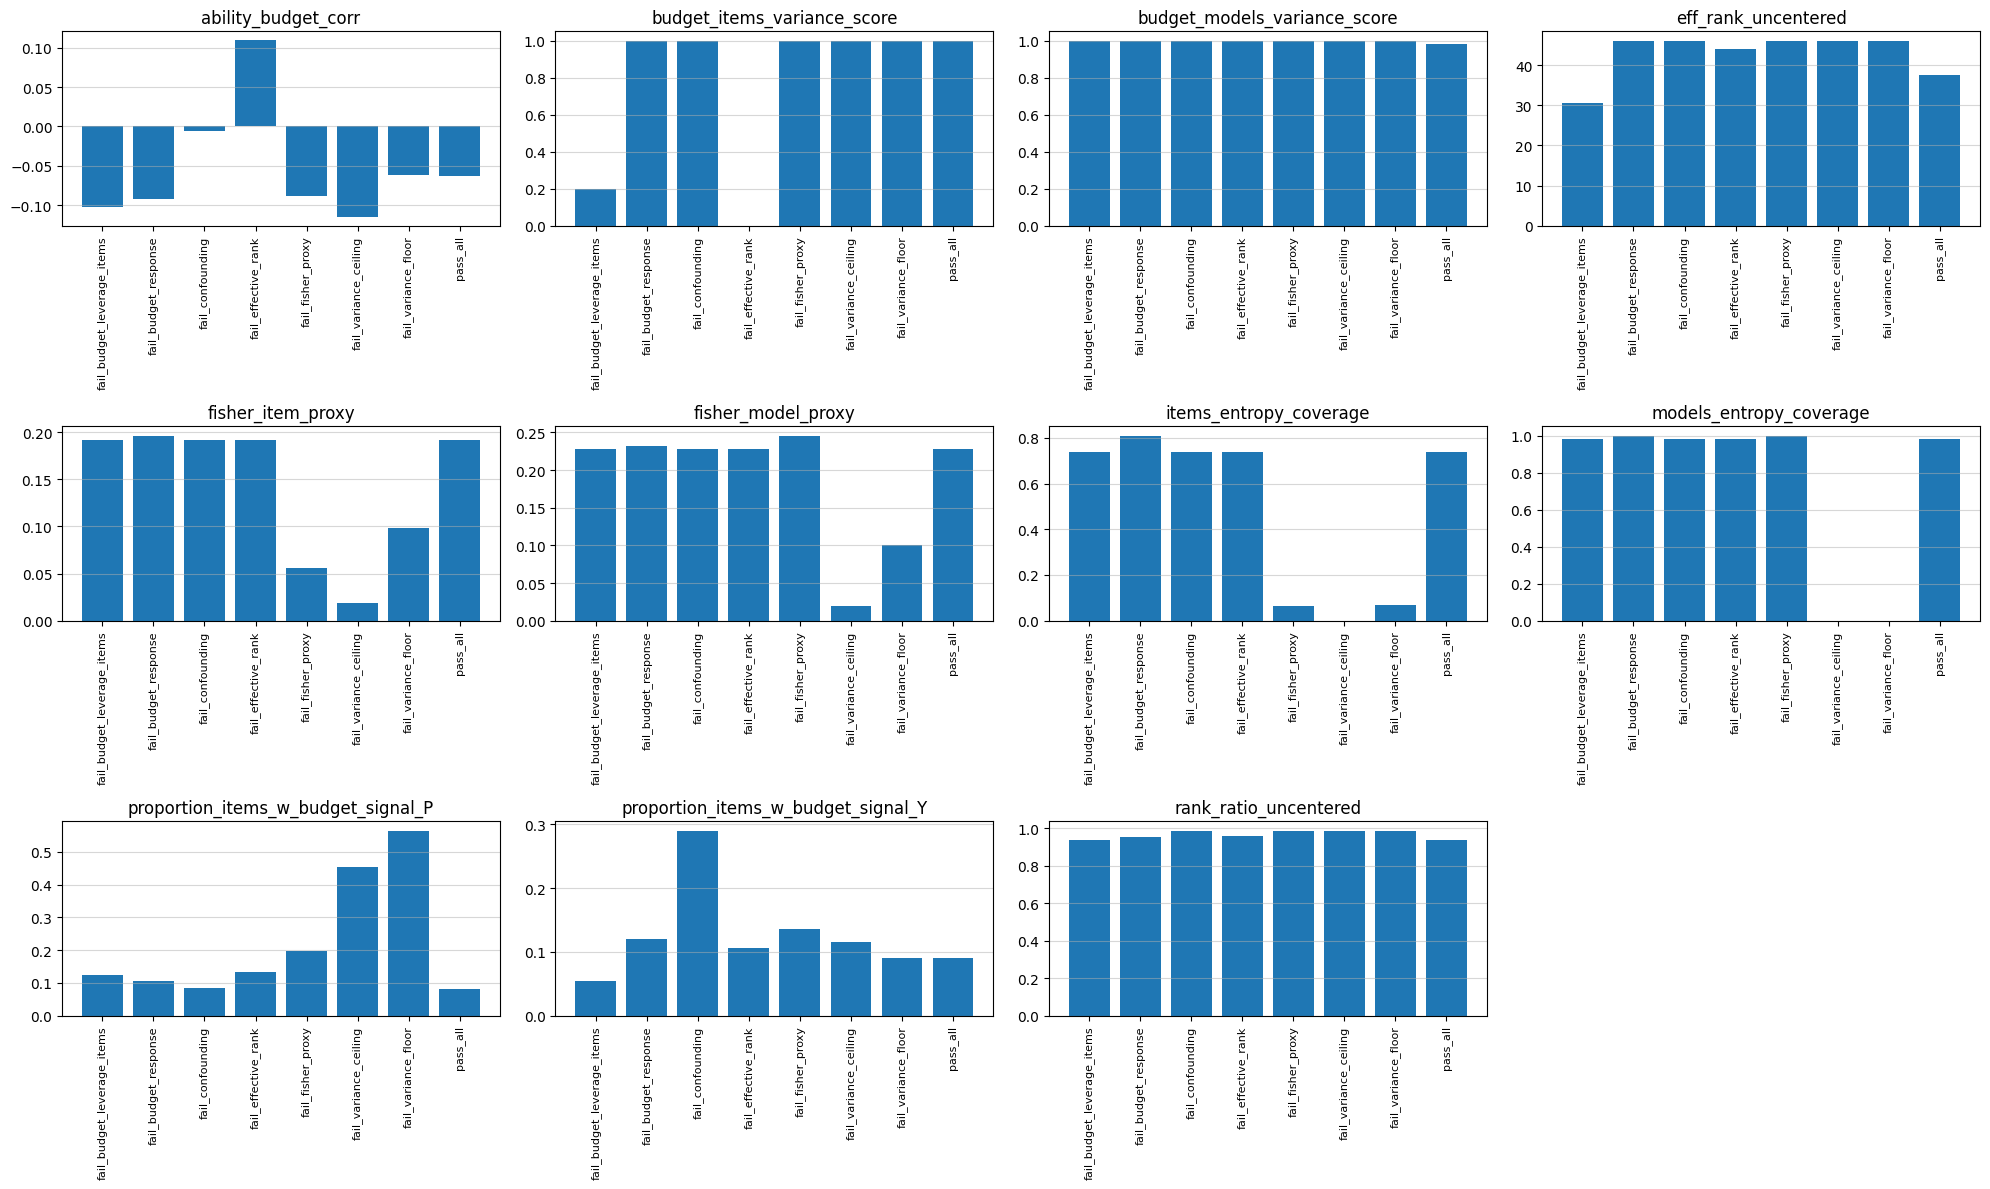

In [4]:
from reasoning_aware_irt.toy_scenarios import plot_precheck_results
import matplotlib.pyplot as plt
# fig, _ = plot_precheck_results(results_list, titles=names, avg_Y_list=avg_Y_list)
fig, _ = plot_precheck_results(all_results)
plt.show() # enable when running as a script

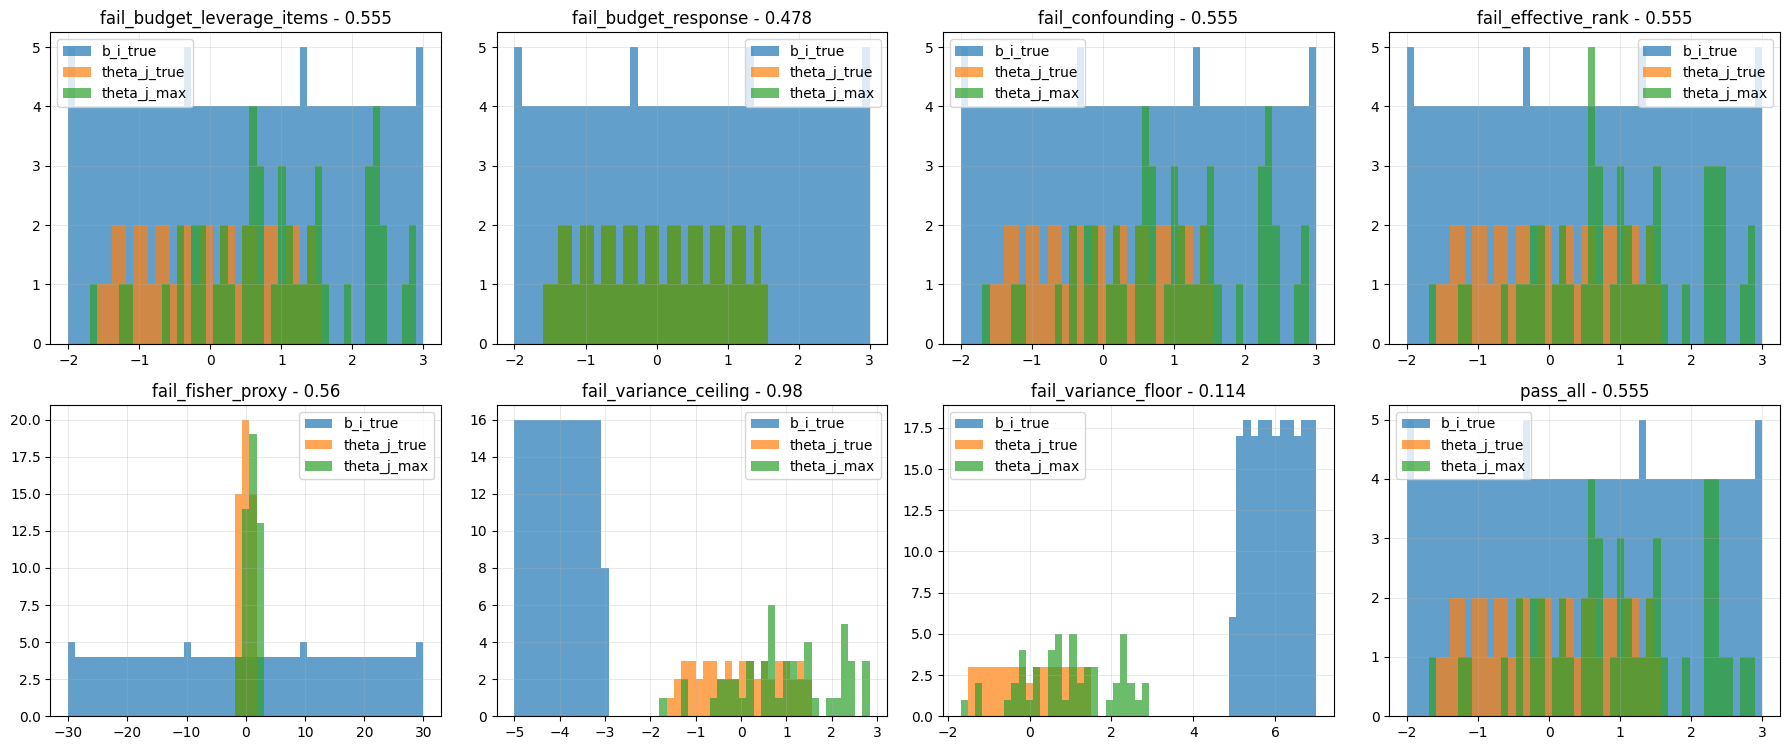

In [5]:
from reasoning_aware_irt.toy_scenarios import plot_multiple_b_theta_histograms
_, _ = plot_multiple_b_theta_histograms(toy_list, toy_data_names=names, plots_per_row=4, avg_Y_list=avg_Y_list)

# Systematic Check - varying #gate-on

In [6]:
print_msg = False

b_span_list = np.linspace(-2.0, 5, 10)

toy_data_name, toy_data_list = [], []
all_results = []
avg_Y_list = []
for b_span in b_span_list:
    toy_data = make_reasoning_aware_3pl_toy(b_span_low=  b_span,
                                           b_span_high= b_span+1,
                                           frac_gate_on=1.0
                                           )
    toy_data_list.append(toy_data)
    toy_data_name.append(str(b_span))

    Y_mean = toy_data['Y_ij'].mean()
    avg_Y_list.append(Y_mean)

    if print_msg:
        print(f"\n--- RUNNING b_span: {b_span} ---")
        print(f"Average of Y = {Y_mean}")

    checker = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data['P_ij'], print_msg=print_msg)
    ok, warn, results = checker.run_all_tests()
    all_results.append(results)

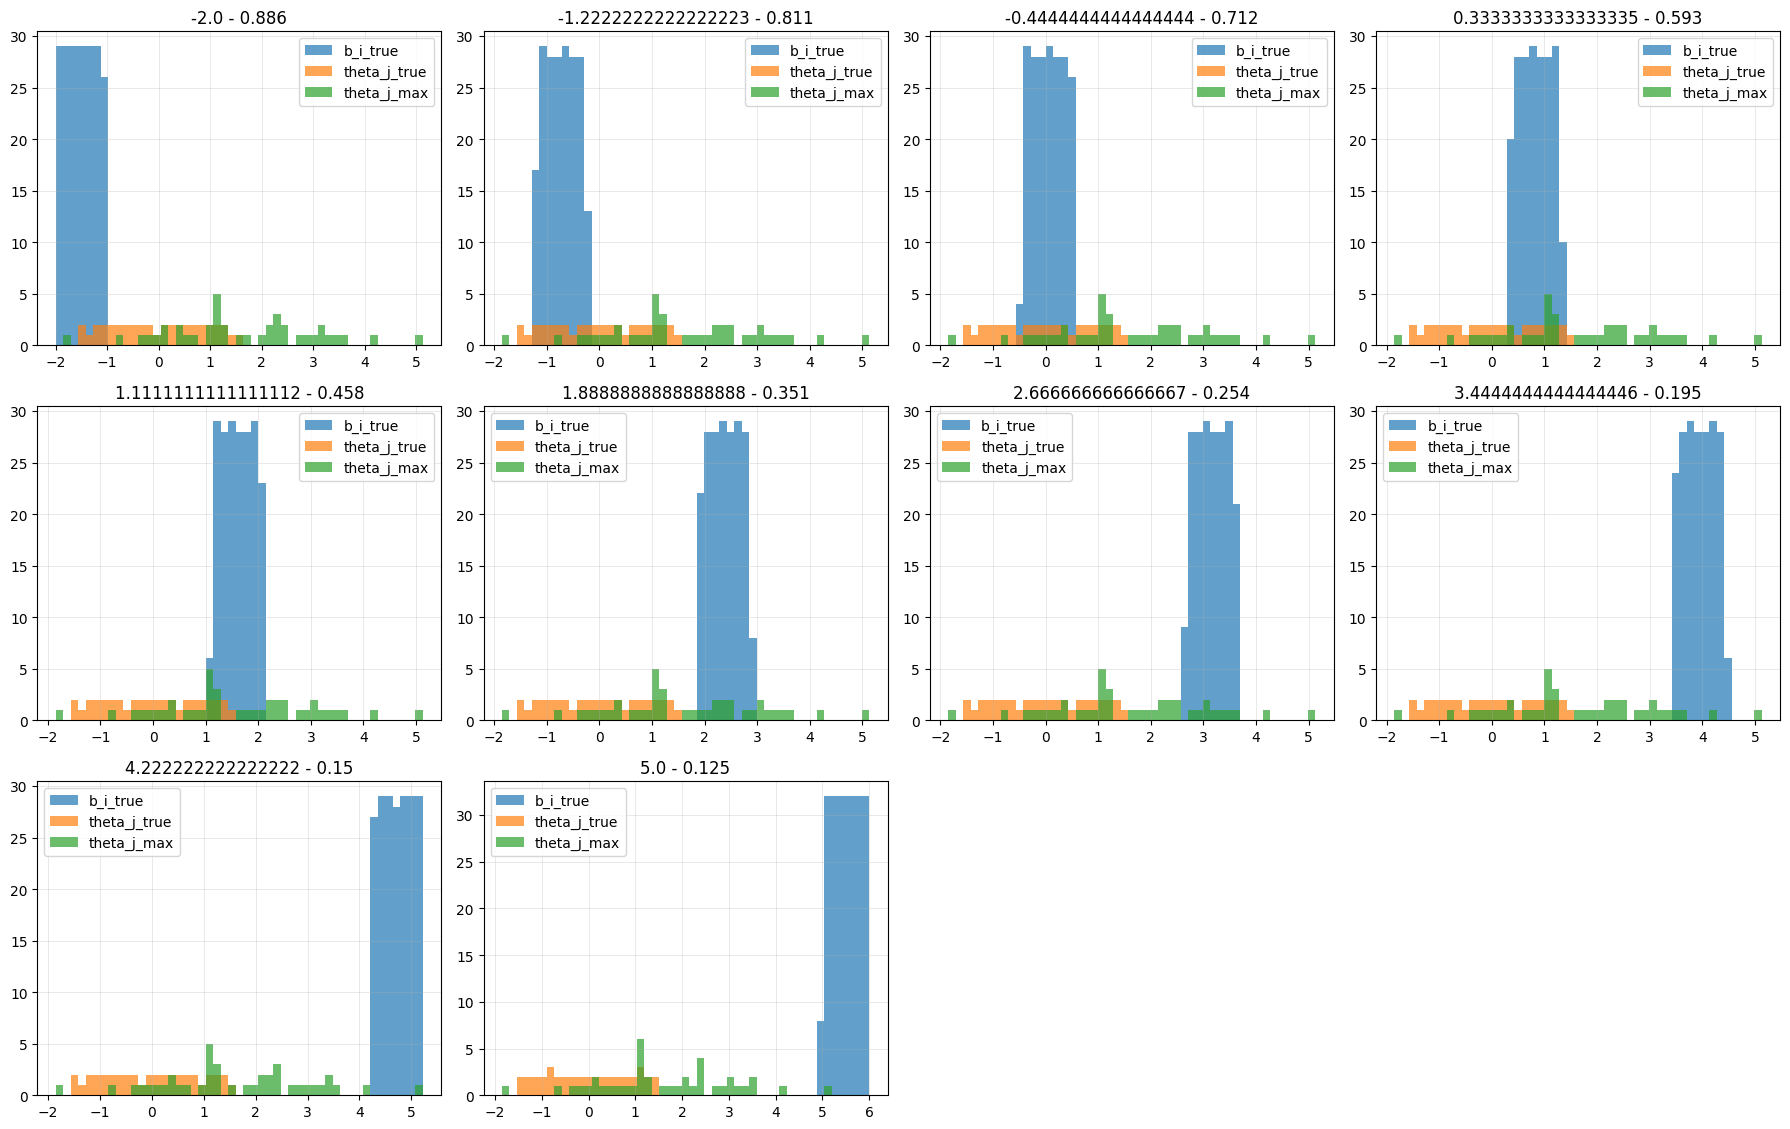

In [7]:
_, _ = plot_multiple_b_theta_histograms(toy_data_list, toy_data_names=toy_data_name, plots_per_row=4, avg_Y_list=avg_Y_list)

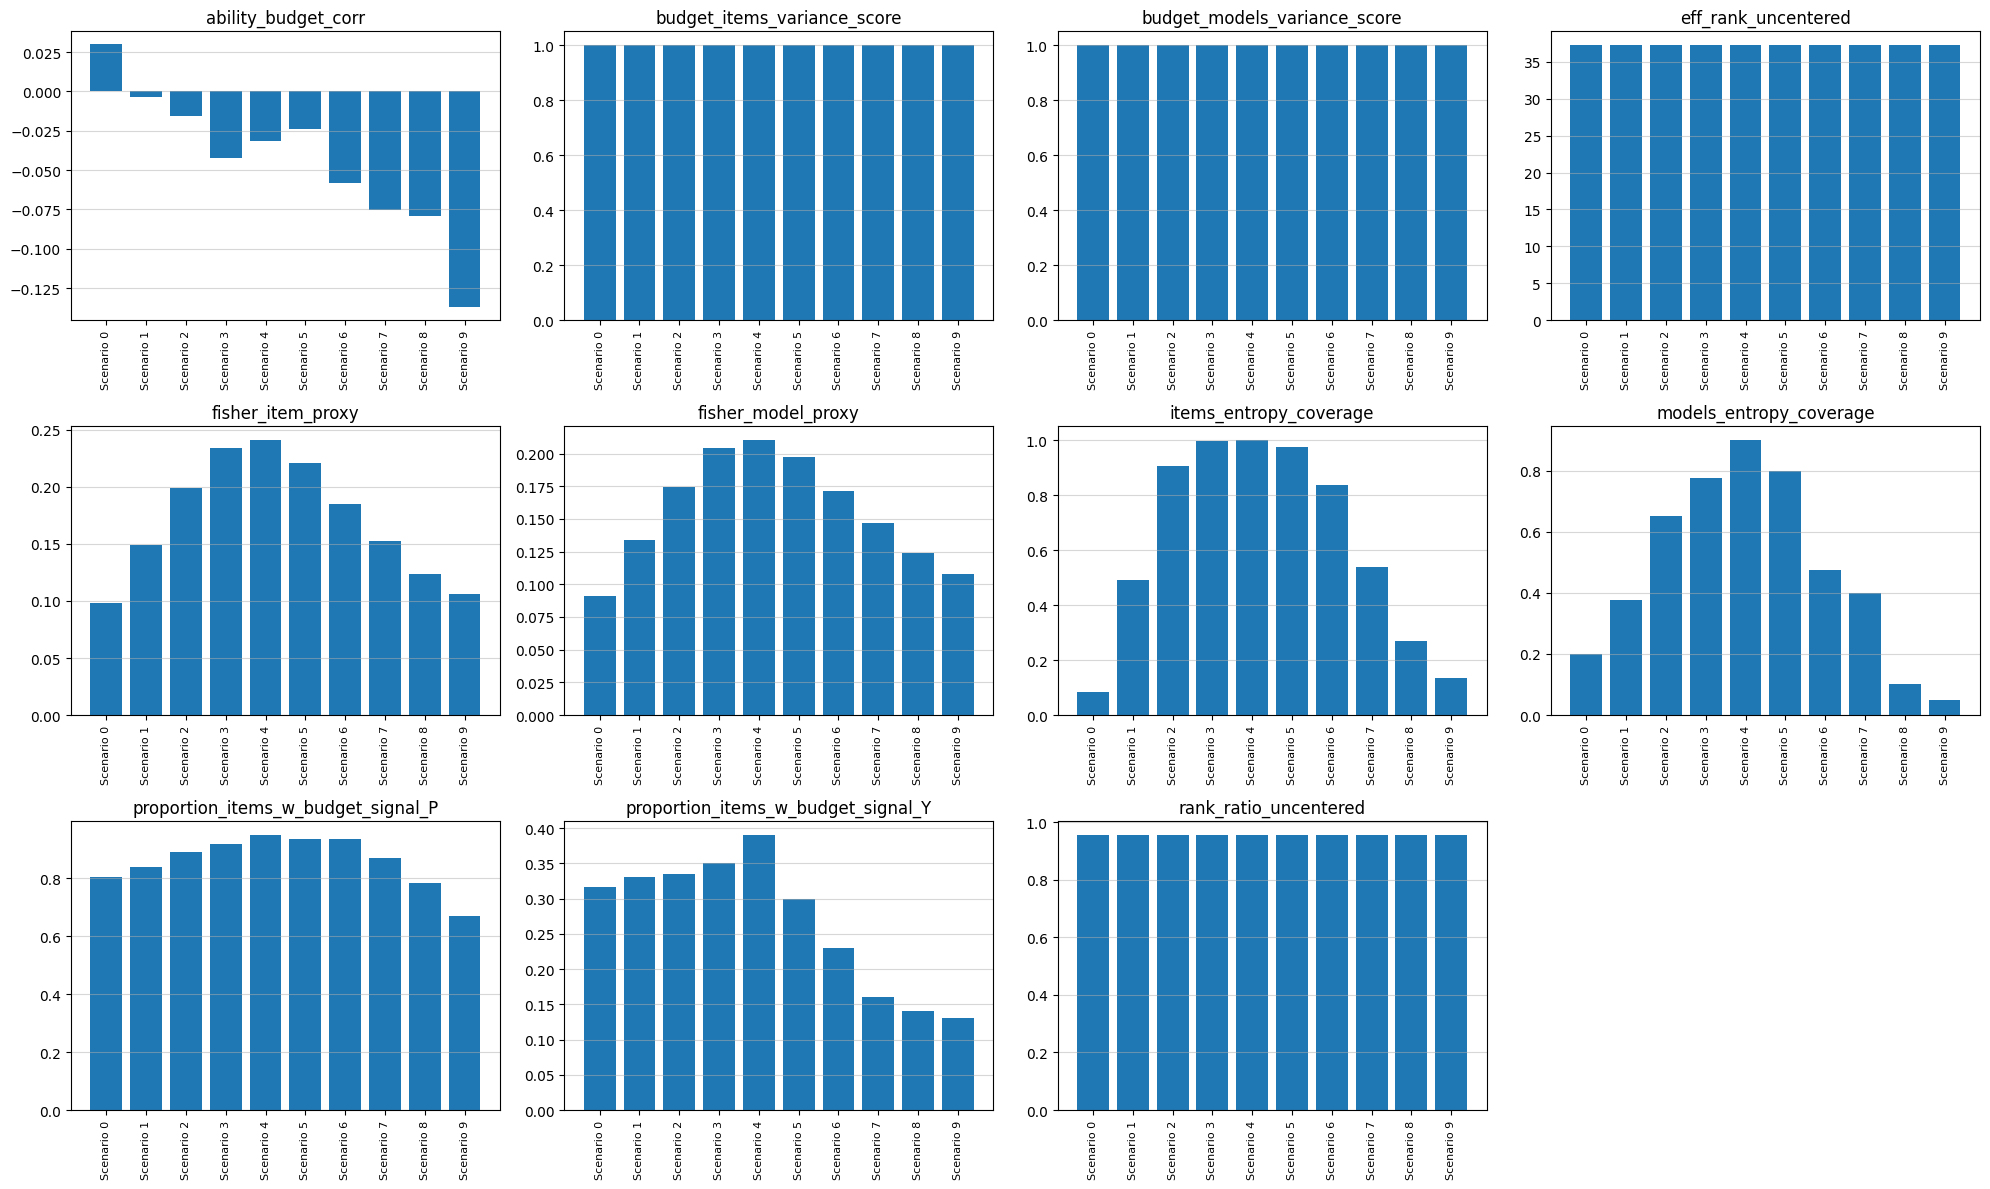

In [9]:
_,_ = plot_precheck_results(all_results)